# 04 — Weekly forecast and backtest

**Question:** how many units will each product sell in each store over the next 1 to 4 weeks, with a low and a high scenario, and how much better than simple rules can a model do?

**Set-up**
- **Target:** weekly units per product × store, 1 to 4 weeks ahead.
- **Known in advance:** the price and promotion plan of the target weeks (promotions are planned weeks ahead — this is the Trade Promotion Management use case). **Not known:** any sales after the forecast date. Every sales-based feature is therefore lagged by at least 4 weeks (`sql/04_forecast_features.sql`).
- **Rolling-origin backtest:** 7 forecast dates over the last 28 weeks. At each date the models are trained on all weeks up to that date and forecast the next 4; the date then moves forward 4 weeks. This mimics how the forecast would have been used in practice.

**Models**
| Model | Idea |
|---|---|
| Seasonal naive | same week last year |
| Moving average | average of weeks t−4 to t−11 |
| Regression | the per-product price and promotion model of notebook 02 |
| LightGBM | one gradient-boosting model for all products, with the promotion calendar, prices, competitors, calendar and lagged sales; plus P10 and P90 quantile models for the low and high scenarios |

**Metrics**
- **WAPE** (decision metric) = Σ|actual − forecast| / Σ actual. Weighted by volume, so it reflects business impact and stays stable for low-volume weeks, unlike MAPE.
- **Bias** = Σ forecast / Σ actual − 1. Positive means over-forecasting (overstock), negative means under-forecasting (stock-outs).
- **Coverage** of the P10–P90 range: should be close to 80 %.

Code: `src/promo_pricing/forecast.py`, tested in `tests/test_forecast.py`. Running the backtest takes about 5 minutes.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from promo_pricing.forecast import load_features, rolling_backtest, wape, bias, coverage

DB, FIG = "../data/frat.duckdb", "../reports/figures/"
pd.set_option("display.width", 200)
MODELS = ["seasonal_naive", "moving_average", "regression", "lightgbm"]
MODEL_LABEL = {"seasonal_naive": "Seasonal naive", "moving_average": "Moving average",
               "regression": "Regression", "lightgbm": "LightGBM"}
CAT_ORDER = ["FROZEN PIZZA", "COLD CEREAL", "ORAL HYGIENE PRODUCTS", "BAG SNACKS"]
CAT_LABEL = {"COLD CEREAL": "Cold cereal", "FROZEN PIZZA": "Frozen pizza",
             "BAG SNACKS": "Pretzels", "ORAL HYGIENE PRODUCTS": "Mouthwash"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 11,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "legend.frameon": False,
})

df = load_features(DB)
bt, importance = rolling_backtest(df, n_folds=7, horizon=4)
print(f"{len(bt):,} forecasts over {bt.week.nunique()} weeks "
      f"({bt.week.min():%Y-%m-%d} to {bt.week.max():%Y-%m-%d}), {bt.origin.nunique()} forecast dates")

93,482 forecasts over 28 weeks (2011-06-29 to 2012-01-04), 7 forecast dates


## 1. Overall accuracy

In [2]:
def scores(d):
    return pd.Series({**{f"WAPE {MODEL_LABEL[m]}": wape(d.units, d[m]) for m in MODELS},
                      **{f"bias {MODEL_LABEL[m]}": bias(d.units, d[m]) for m in MODELS}})

segments = {"All weeks": bt, "Weeks without promotion": bt[bt.any_promo == 0], "Promotion weeks": bt[bt.any_promo == 1]}
overall = pd.DataFrame({k: scores(v) for k, v in segments.items()}).T
(100 * overall).round(1)

,WAPE Seasonal naive,WAPE Moving average,WAPE Regression,WAPE LightGBM,bias Seasonal naive,bias Moving average,bias Regression,bias LightGBM
All weeks,60.2,44.7,34.3,28.4,4.3,-0.7,1.8,-0.0
Weeks without promotion,61.2,40.4,32.7,26.8,25.8,20.8,-0.8,1.9
Promotion weeks,58.6,51.7,36.9,31.0,-30.1,-35.2,5.9,-3.1


In [3]:
fva = pd.DataFrame({
    "WAPE LightGBM (%)": 100 * overall["WAPE LightGBM"],
    "vs moving average (% error removed)": 100 * (1 - overall["WAPE LightGBM"] / overall["WAPE Moving average"]),
    "vs seasonal naive (% error removed)": 100 * (1 - overall["WAPE LightGBM"] / overall["WAPE Seasonal naive"]),
})
fva.round(0)

,WAPE LightGBM (%),vs moving average (% error removed),vs seasonal naive (% error removed)
All weeks,28.0,36.0,53.0
Weeks without promotion,27.0,34.0,56.0
Promotion weeks,31.0,40.0,47.0


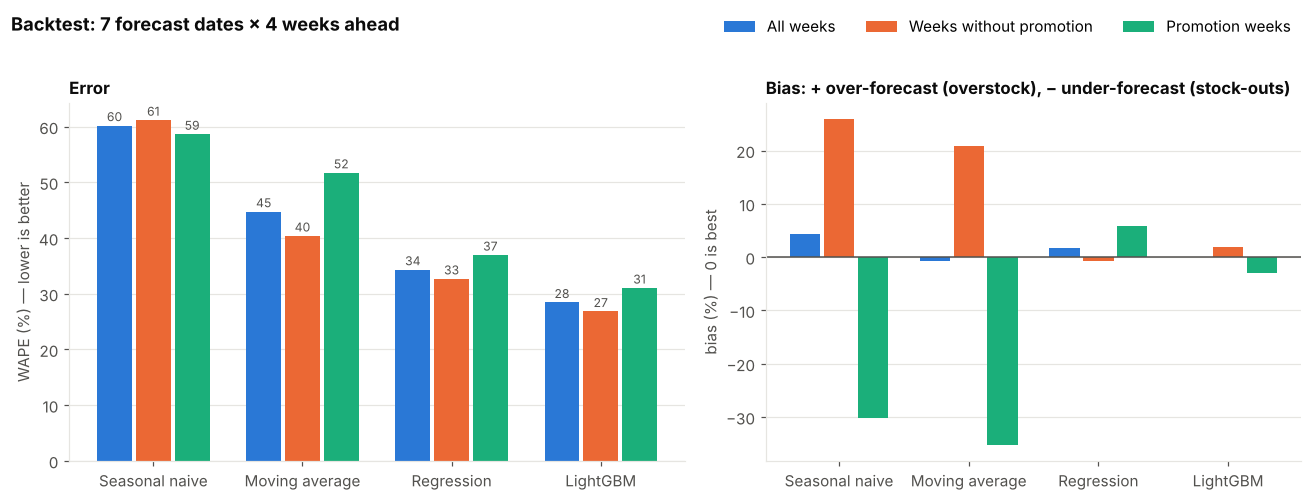

In [4]:
SEG_COLOR = {"All weeks": "#2a78d6", "Weeks without promotion": "#eb6834", "Promotion weeks": "#1baf7a"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
x = np.arange(len(MODELS)); w = 0.26
for i, seg in enumerate(segments):
    v = [100 * overall.loc[seg, f"WAPE {MODEL_LABEL[m]}"] for m in MODELS]
    bars = a1.bar(x + (i - 1) * w, v, w * 0.9, color=SEG_COLOR[seg], label=seg)
    for b, val in zip(bars, v):
        a1.text(b.get_x() + b.get_width() / 2, val + 0.8, f"{val:.0f}", ha="center", fontsize=8, color=INK2)
    vb = [100 * overall.loc[seg, f"bias {MODEL_LABEL[m]}"] for m in MODELS]
    a2.bar(x + (i - 1) * w, vb, w * 0.9, color=SEG_COLOR[seg])
a1.set_xticks(x, [MODEL_LABEL[m] for m in MODELS]); a2.set_xticks(x, [MODEL_LABEL[m] for m in MODELS])
a1.set_ylabel("WAPE (%) — lower is better"); a1.set_title("Error")
a2.axhline(0, color=INK2, lw=1); a2.set_ylabel("bias (%) — 0 is best")
a2.set_title("Bias: + over-forecast (overstock), − under-forecast (stock-outs)")
for a in (a1, a2): a.grid(axis="x", visible=False)
fig.legend(*a1.get_legend_handles_labels(), loc="upper right", ncol=3, bbox_to_anchor=(0.99, 1.04))
fig.suptitle("Backtest: 7 forecast dates × 4 weeks ahead", x=0.01, y=1.02, ha="left", fontweight="bold", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIG + "09_forecast_accuracy.png", bbox_inches="tight")

**Findings**
- **LightGBM is the most accurate model**: WAPE 28 % against 45 % for the moving average and 60 % for the seasonal naive. It removes about **36 % of the moving-average error** and over half of the seasonal-naive error, with **no overall bias**.
- **Simple rules fail precisely on promotion weeks.** The moving average under-forecasts them by 35 % (stock-outs) and over-forecasts normal weeks by 21 % (overstock), because it averages promoted and normal weeks together. Models that know the promotion calendar keep the bias within a few percent in both cases.
- **Same week last year is the worst rule** (WAPE 60 %): last year's promotion calendar was different, so it copies promotion peaks into the wrong weeks.
- The regression of notebook 02 already captures most of the gain (WAPE 34 %); LightGBM adds the recent sales level and the interactions between promotions, stores and products.

## 2. By category and by horizon

In [5]:
cat = bt.groupby("category").apply(lambda d: pd.Series(
    {**{f"WAPE {MODEL_LABEL[m]}": wape(d.units, d[m]) for m in MODELS},
     "bias LightGBM": bias(d.units, d.lightgbm), "weekly units per series": d.units.mean()}), include_groups=False)
cat = cat.loc[CAT_ORDER].rename(index=CAT_LABEL)
cat.iloc[:, :5] = 100 * cat.iloc[:, :5]
cat.round(1)

,WAPE Seasonal naive,WAPE Moving average,WAPE Regression,WAPE LightGBM,bias LightGBM,weekly units per series
category,,,,,,
Frozen pizza,67.9,51.6,36.1,32.9,-1.0,11.6
Cold cereal,65.5,49.8,35.9,28.2,1.1,33.6
Mouthwash,62.3,53.7,42.4,40.1,-1.9,4.6
Pretzels,43.9,27.8,28.0,23.6,-1.4,18.5


In [6]:
hor = bt.groupby("horizon").apply(lambda d: pd.Series(
    {f"WAPE {MODEL_LABEL[m]} (%)": 100 * wape(d.units, d[m]) for m in MODELS}), include_groups=False)
hor.index = [f"{int(h)} week(s) ahead" for h in hor.index]
hor.round(1)

,WAPE Seasonal naive (%),WAPE Moving average (%),WAPE Regression (%),WAPE LightGBM (%)
1 week(s) ahead,61.3,46.1,32.8,26.3
2 week(s) ahead,60.9,46.6,33.5,28.4
3 week(s) ahead,60.1,44.2,35.4,30.0
4 week(s) ahead,58.6,42.1,35.5,29.0


- **Mouthwash is the hardest category** (WAPE 40 %): it sells fewer than 5 units per store and week on average, and with such small counts much of the variation is pure chance. Pretzels, a more regular category, are the easiest (24 %).
- **Accuracy barely degrades from 1 to 4 weeks ahead** (26 % → 29 %): the promotion calendar, known in advance, carries most of the information.

## 3. Low and high scenarios (P10 – P90)

For each forecast, the quantile models give a **low scenario** (P10: sales should be below it only 10 % of the time) and a **high scenario** (P90). A range is only useful if it is honest, so its coverage is checked on the backtest.

In [7]:
cov = pd.Series({k: coverage(v.units, v.lightgbm_p10, v.lightgbm_p90) for k, v in segments.items()}, name="coverage (target 80 %)")
cov_cat = bt.groupby("category").apply(lambda d: coverage(d.units, d.lightgbm_p10, d.lightgbm_p90), include_groups=False)
cov_cat.index = cov_cat.index.map(CAT_LABEL)
print((100 * pd.concat([cov, cov_cat])).round(1).to_string())
print(f"\nAverage width of the range: {(bt.lightgbm_p90 - bt.lightgbm_p10).mean():.1f} units "
      f"for an average forecast of {bt.lightgbm.mean():.1f} units")

All weeks                  76.3
Weeks without promotion    76.4
Promotion weeks            76.0
Pretzels                   78.7
Cold cereal                75.2
Frozen pizza               77.2
Mouthwash                  74.1

Average width of the range: 16.2 units for an average forecast of 18.2 units


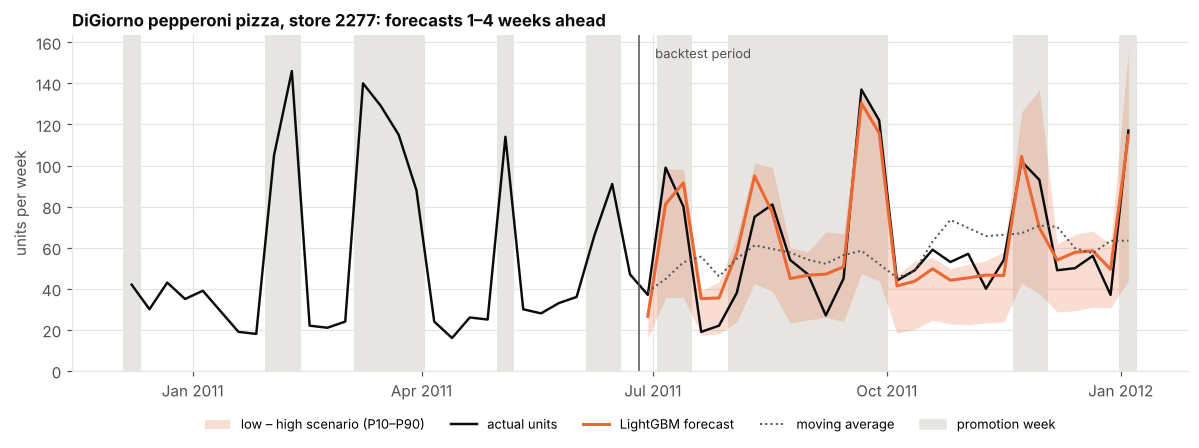

In [8]:
ex_upc, ex_store = 7192100339, 2277      # DiGiorno pepperoni, the store of notebook 03
hist = df[(df.upc == ex_upc) & (df.store_id == ex_store) & (df.week_index >= 100)].sort_values("week")
f = bt[(bt.upc == ex_upc) & (bt.store_id == ex_store)].sort_values("week")

fig, ax = plt.subplots(figsize=(11, 4.2))
for wk in hist.loc[hist.any_promo == 1, "week"]:
    ax.axvspan(wk - pd.Timedelta(days=3.5), wk + pd.Timedelta(days=3.5), color=GRID, lw=0)
ax.fill_between(f.week, f.lightgbm_p10, f.lightgbm_p90, color="#eb6834", alpha=0.22, lw=0, label="low – high scenario (P10–P90)")
ax.plot(hist.week, hist.units, color=INK, lw=1.6, label="actual units")
ax.plot(f.week, f.lightgbm, color="#eb6834", lw=2, label="LightGBM forecast")
ax.plot(f.week, f.moving_average, color=INK2, lw=1.3, ls=":", label="moving average")
ax.axvline(f.week.min() - pd.Timedelta(days=3.5), color=INK2, lw=1)
ax.text(f.week.min(), ax.get_ylim()[1] * 0.97, "  backtest period", va="top", fontsize=8.5, color=INK2)
ax.fill_between([], [], color=GRID, label="promotion week")
ax.set_ylim(bottom=0); ax.set_ylabel("units per week")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("DiGiorno pepperoni pizza, store 2277: forecasts 1–4 weeks ahead")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG + "10_forecast_example.png", bbox_inches="tight")

**Findings**
- The P10–P90 range contains the actual sales **about 76 % of the time, slightly below the 80 % target**: the range is a little too narrow and should be widened before use, for example by calibrating it on the errors of past forecast dates (conformal calibration).
- Coverage is similar in promotion and normal weeks, so the high scenario does widen when a promotion is planned, as the example shows.
- **These ranges are for one product in one store.** Adding up P10s across products or stores does *not* give the P10 of the total: the total's range is narrower, because errors partly cancel out. Category-level scenarios need their own quantile model or simulation.

## 4. What drives the forecast

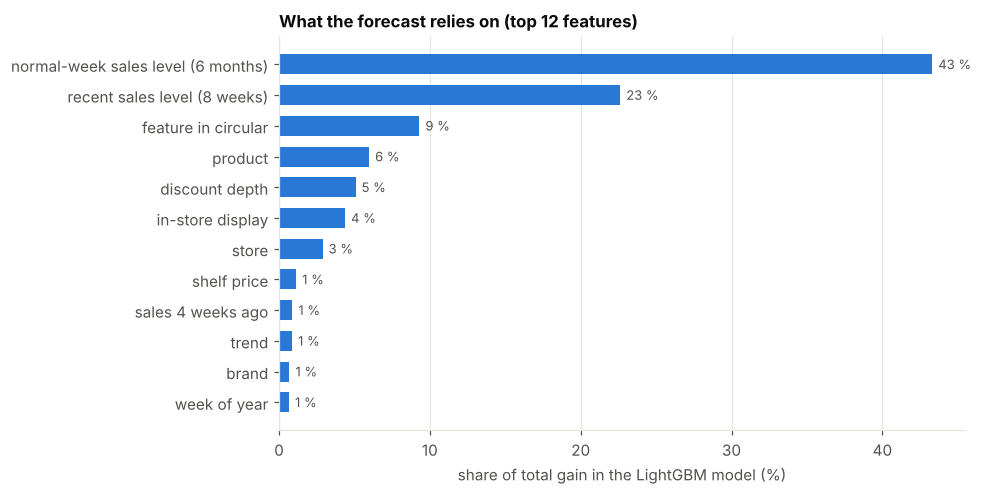

In [9]:
top = importance.head(12)[::-1]
share = 100 * top / importance.sum()
names = {"units_nopromo_avg26_lag4": "normal-week sales level (6 months)", "units_ma8_lag4": "recent sales level (8 weeks)",
         "feature": "feature in circular", "upc": "product", "discount_depth": "discount depth", "display": "in-store display",
         "store_id": "store", "log_price": "shelf price", "units_lag4": "sales 4 weeks ago", "week_index": "trend",
         "manufacturer": "brand", "week_of_year": "week of year", "tpr_only": "price cut only", "log_base_price": "base price",
         "units_lag52": "sales same week last year", "competitor_avg_discount": "competitors' discount",
         "promo_weeks_last_4": "promotions in last 4 weeks", "units_lag5": "sales 5 weeks ago", "units_lag8": "sales 8 weeks ago",
         "category": "category", "competitor_promo_share": "competitors on promotion"}
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh([names.get(i, i) for i in top.index], share, color="#2a78d6", height=0.65)
for yi, v in enumerate(share):
    ax.text(v + 0.4, yi, f"{v:.0f} %", va="center", fontsize=8.5, color=INK2)
ax.set_xlabel("share of total gain in the LightGBM model (%)")
ax.set_title("What the forecast relies on (top 12 features)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG + "11_forecast_drivers.png", bbox_inches="tight")

The forecast rests on two things: **the product's normal sales level** in that store, and **the promotion plan of the target week** (feature, discount depth, display, price). This matches notebooks 02 and 03: knowing the promotion calendar is what makes a forecast accurate, and it is exactly the information a promotion-planning tool holds.

## Summary

| | Seasonal naive | Moving average | Regression | **LightGBM** |
|---|---|---|---|---|
| WAPE, all weeks | 60 % | 45 % | 34 % | **28 %** |
| Bias, promotion weeks | −30 % | −35 % | +6 % | **−3 %** |
| Bias, normal weeks | +26 % | +21 % | −1 % | **+2 %** |

**Recommendation:** use LightGBM as the weekly forecast, with the P10–P90 range as low and high scenarios after calibration; keep the moving average as a monitoring benchmark — if LightGBM stops beating it, the model needs retraining.

**Limits**
- Weeks with no record (product not sold or not listed) are not forecast: zero sales cannot be distinguished from missing data in this dataset.
- The promotion plan is assumed to be executed as planned; in reality, last-minute changes add error.
- Hyper-parameters were set once, not tuned; tuning on earlier folds could gain a little more.
- The P10–P90 range is slightly too narrow (76 % coverage) and applies to single product-store series only.